1.Project Overview
1.1 Introduction
This project focuses on analyzing retail store sales and building predictive machine learning models using historical data from Walmart stores. The data spans from February 2010 to October 2012 across 45 different stores and captures weekly sales figures alongside crucial external economic and environmental indicators, such as macroeconomic factors (Consumer Price Index [CPI], Unemployment Rate), fuel prices, weather conditions (Temperature), and special holiday weeks.

1.2 Problem Statement
Retail corporations like Walmart face significant operational challenges due to unforeseen demand fluctuations, which can result in either costly overstocking or lost revenue from stockouts. Traditional forecasting often fails to accurately ingest complex, multi-variate factors—such as seasonal spikes during holiday weeks, shifting macroeconomic conditions (CPI and unemployment), and regional pricing pressures (fuel prices). Without a robust machine learning algorithm, predicting exact weekly sales across various branches remains prone to high error rates.

1.3 Purpose of the Project
The primary goals of this project are:
Exploratory Data Analysis (EDA): To clean, inspect, and visualize the dataset, uncovering underlying trends, seasonal distributions, and correlations between weekly sales and external features.
Predictive Modeling: To build and evaluate advanced regression algorithms (including Random Forest Regressor, GradientBoostingRegressor, and Ridge Regression) capable of predicting weekly sales accurately.
Performance Evaluation: To compare models using standard regression metrics such as Mean Absolute Error (MAE), Mean Squared Error (MSE), and the Coefficient of Determination (R^2 Score) to identify the optimal forecasting pipeline.

## IMPORT LIBRARIES

In [87]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

## LOAD DATA USING PANDAS

In [88]:
wallmart_df = pd.read_csv(r"C:\Users\user\Downloads\walmart dataset\Walmart.csv")

In [89]:
wallmart_df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


In [91]:
wallmart_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [92]:
wallmart_df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


### Plot histogram

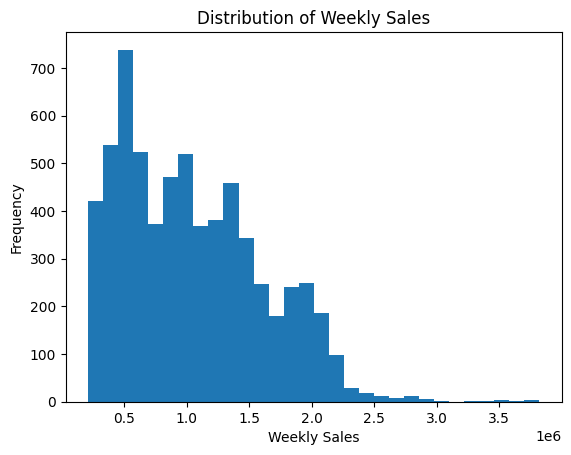

In [93]:

plt.figure()
plt.hist(wallmart_df['Weekly_Sales'], bins=30)
plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales")
plt.ylabel("Frequency")
plt.show()

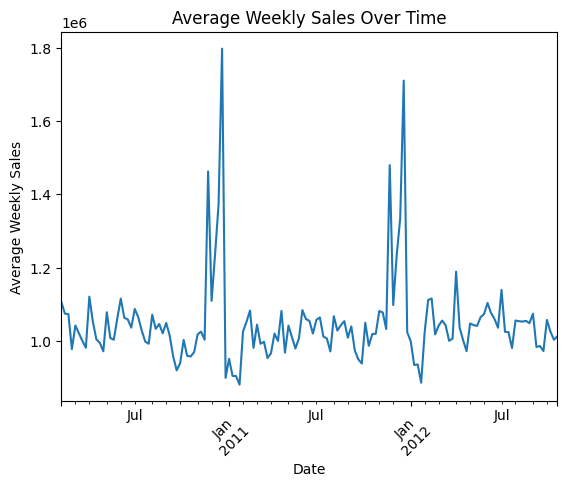

In [94]:
# If Date exists (if not, reload original dataset instead)
if 'Date' in wallmart_df.columns:
    wallmart_df['Date'] = pd.to_datetime(
    wallmart_df['Date'],
    dayfirst=True
)
    
    plt.figure()
    wallmart_df.sort_values('Date') \
      .groupby('Date')['Weekly_Sales'] \
      .mean() \
      .plot()
    
    plt.title("Average Weekly Sales Over Time")
    plt.xlabel("Date")
    plt.ylabel("Average Weekly Sales")
    plt.xticks(rotation=45)
    plt.show()

### Compute correlation

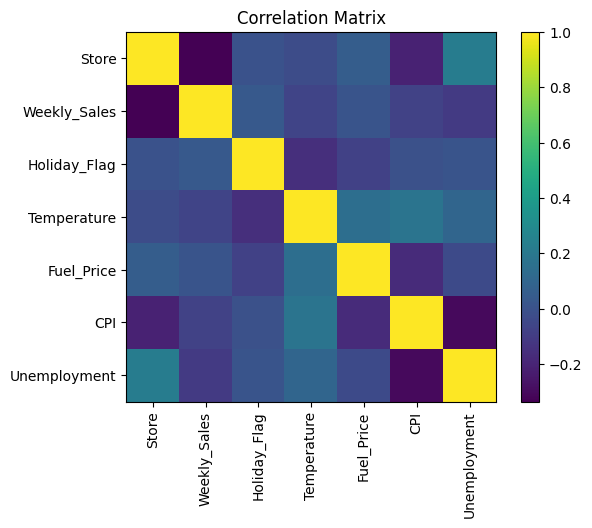

In [95]:

corr = wallmart_df.corr(numeric_only=True)

# Plot heatmap using matplotlib only
plt.figure()
plt.imshow(corr)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.show()

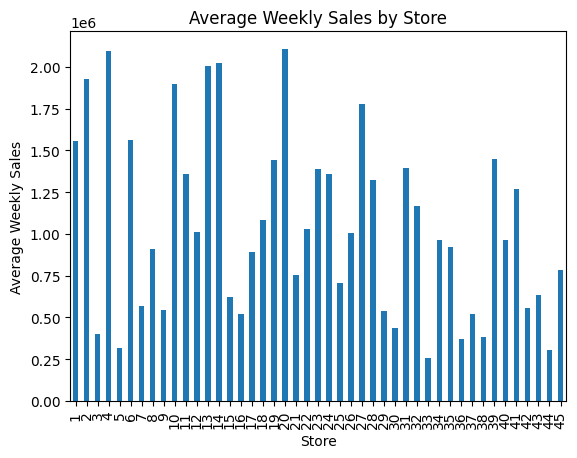

In [96]:
avg_sales_store = wallmart_df.groupby('Store')['Weekly_Sales'].mean()

plt.figure()
avg_sales_store.plot(kind='bar')
plt.title("Average Weekly Sales by Store")
plt.xlabel("Store")
plt.ylabel("Average Weekly Sales")
plt.show()

In [97]:
wallmart_df['Date'] = pd.to_datetime(wallmart_df['Date'], format='%d-%m-%Y')
wallmart_df['Month'] = wallmart_df['Date'].dt.month
wallmart_df['Year'] = wallmart_df['Date'].dt.year
wallmart_df['WeekOfYear'] = wallmart_df['Date'].dt.isocalendar().week.astype(int)

# Drop original Date column
wallmart_df = wallmart_df.drop('Date', axis=1)

# One-hot encoding for the 'Store' column
wallmart_df = pd.get_dummies(wallmart_df, columns=['Store'], drop_first=True)

## Define Features (X) and Target (y)

In [98]:

X = wallmart_df.drop('Weekly_Sales', axis=1)
y = wallmart_df['Weekly_Sales']

In [99]:
X.shape, y.shape

((6435, 52), (6435,))

In [100]:
wallmart_df.head()

,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Month,Year,WeekOfYear,Store_2,...,Store_36,Store_37,Store_38,Store_39,Store_40,Store_41,Store_42,Store_43,Store_44,Store_45
0,1643690.90,0,42.31,2.572,211.096358,8.106,2,2010,5,False,...,False,False,False,False,False,False,False,False,False,False
1,1641957.44,1,38.51,2.548,211.242170,8.106,2,2010,6,False,...,False,False,False,False,False,False,False,False,False,False
2,1611968.17,0,39.93,2.514,211.289143,8.106,2,2010,7,False,...,False,False,False,False,False,False,False,False,False,False
3,1409727.59,0,46.63,2.561,211.319643,8.106,2,2010,8,False,...,False,False,False,False,False,False,False,False,False,False
4,1554806.68,0,46.50,2.625,211.350143,8.106,3,2010,9,False,...,False,False,False,False,False,False,False,False,False,False


## Split into Training (80%) and Testing (20%) sets

In [101]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Initialize, train, Predict, and evaluate RandomForestRegressor model

In [102]:

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)


y_pred_rf = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_rf)
mse = mean_squared_error(y_test, y_pred_rf)
r2 = r2_score(y_test, y_pred_rf)

print("R^2 Score:",r2)
print("Mean Squared Error:",mse)
print("Mean Absolute Error:",mae)


R^2 Score: 0.9471837507896123
Mean Squared Error: 17014995769.959213
Mean Absolute Error: 64760.79152447551


## Initialize, train, Predict, and evaluate GradientBoostingRegressor model

In [103]:

gbm_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gbm_model.fit(X_train, y_train)


y_pred_gbm = gbm_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred_gbm)
mse = mean_squared_error(y_test, y_pred_gbm)
r2 = r2_score(y_test, y_pred_gbm)

print("R^2 Score:",r2)
print("Mean Squared Error:",mse)
print("Mean Absolute Error:",mae)

R^2 Score: 0.8356490652247279
Mean Squared Error: 52946403839.67489
Mean Absolute Error: 187330.71533284985


## Scale the data
## Train,  Predict, and  Evaluate Ridge Regression model

In [104]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

 
ridge_model = Ridge(alpha=1.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train)


y_pred_ridge = ridge_model.predict(X_test_scaled)


print("R² Score:", r2_score(y_test, y_pred_ridge))
print("MSE:", mean_squared_error(y_test, y_pred_ridge))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))

R² Score: 0.925656666232846
MSE: 23950044323.177807
MAE: 96123.13391937004


## Create a figure with 3 subplots

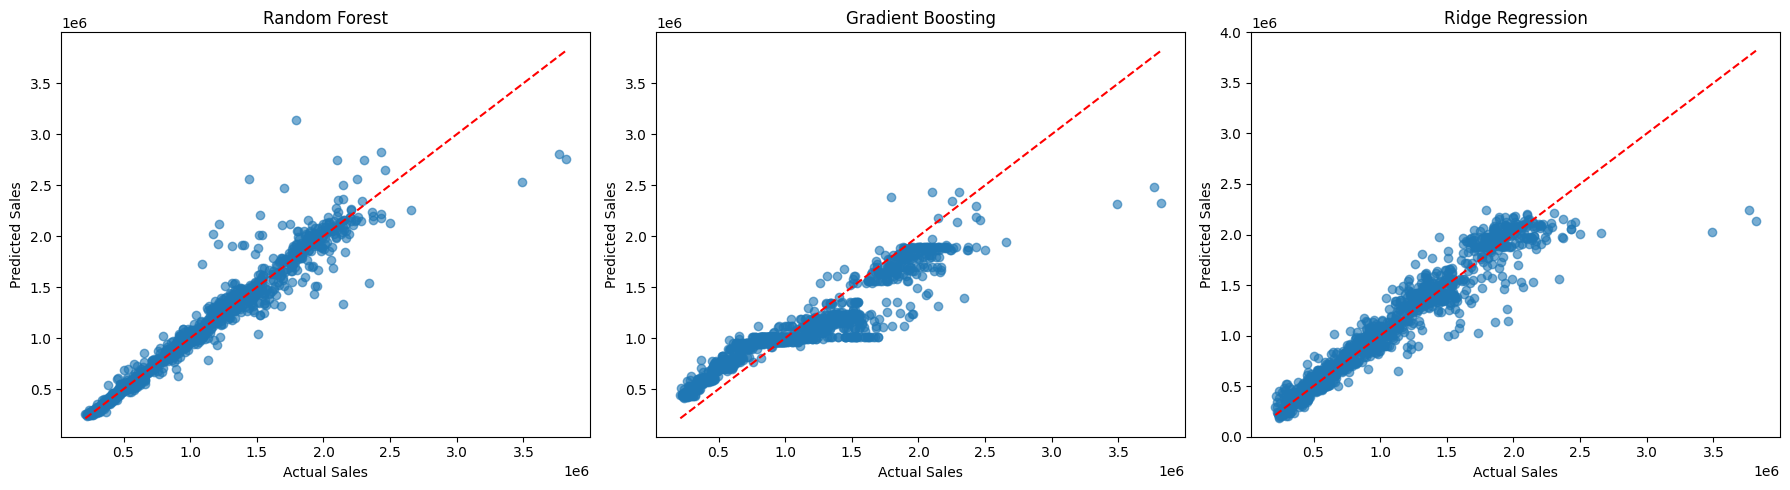

In [105]:


fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Random Forest
axes[0].scatter(y_test, y_pred_rf, alpha=0.6)
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[0].set_title('Random Forest')
axes[0].set_xlabel('Actual Sales')
axes[0].set_ylabel('Predicted Sales')

# Gradient Boosting
axes[1].scatter(y_test, y_pred_gbm, alpha=0.6)
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[1].set_title('Gradient Boosting')
axes[1].set_xlabel('Actual Sales')
axes[1].set_ylabel('Predicted Sales')

# Ridge Regression
axes[2].scatter(y_test, y_pred_ridge, alpha=0.6)
axes[2].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
axes[2].set_title('Ridge Regression')
axes[2].set_xlabel('Actual Sales')
axes[2].set_ylabel('Predicted Sales')

plt.tight_layout()
plt.show()

##  Visualization of Forecast for  RandomForestRegressor, GradientBoostingRegressor, and Ridge Regression models

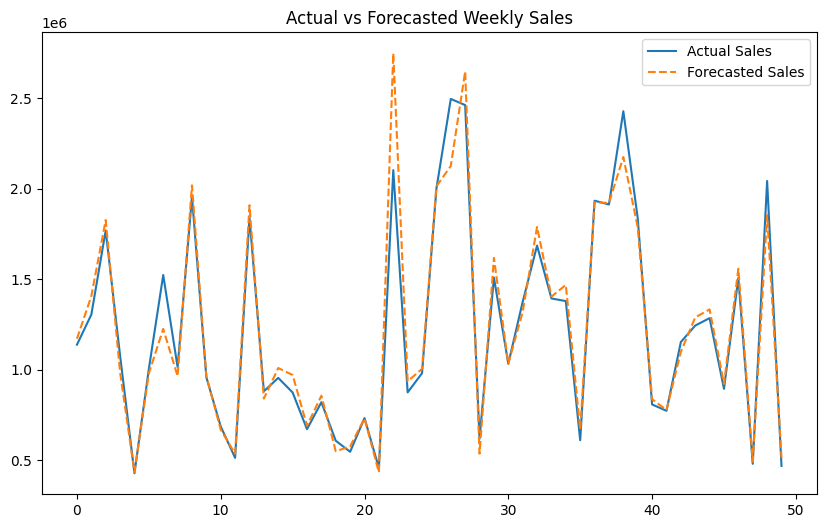

In [106]:
# Visualization of Forecast
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.plot(y_test.values[:50], label='Actual Sales')
plt.plot(y_pred_rf[:50], label='Forecasted Sales', linestyle='--')
plt.legend()
plt.title("Actual vs Forecasted Weekly Sales")
plt.show()

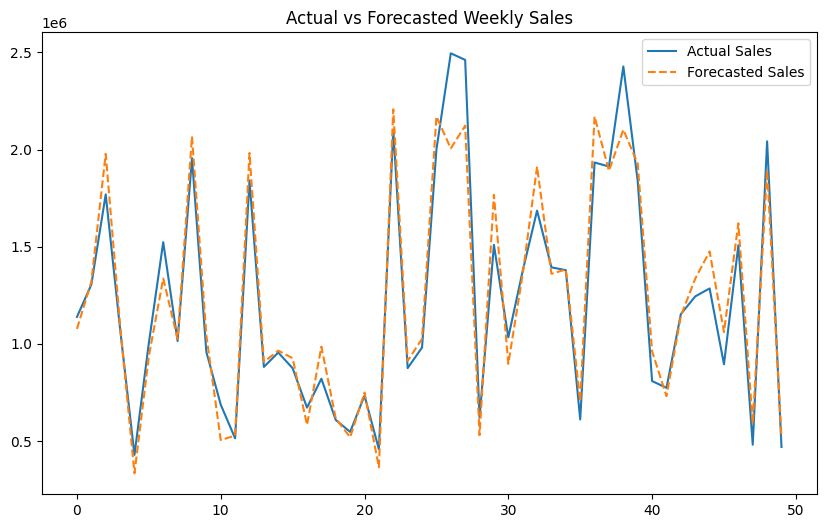

In [107]:
# Visualization of Forecast
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.plot(y_test.values[:50], label='Actual Sales')
plt.plot(y_pred_ridge[:50], label='Forecasted Sales', linestyle='--')
plt.legend()
plt.title("Actual vs Forecasted Weekly Sales")
plt.show()

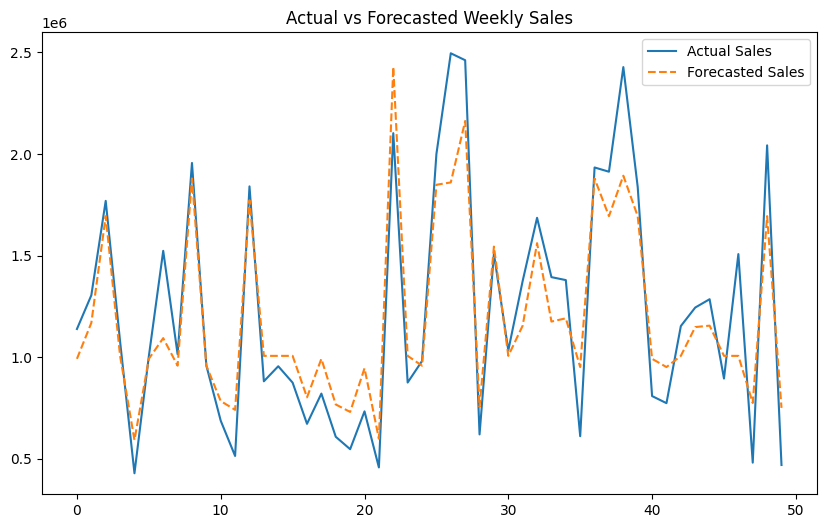

In [108]:
# Visualization of Forecast
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.plot(y_test.values[:50], label='Actual Sales')
plt.plot(y_pred_gbm[:50], label='Forecasted Sales', linestyle='--')
plt.legend()
plt.title("Actual vs Forecasted Weekly Sales")
plt.show()

2.Conclusion and Key Insights
Dataset Scale and Integrity: The historical dataset consists of 6,435 complete records across 8 core variables with zero missing values, providing a clean foundation for modeling.

Sales Distribution: Weekly sales exhibit significant right-skewness and variance, heavily driven by specific high-performing store locations and periodic holiday surges (e.g., Thanksgiving and Christmas weeks).

Model Performance: Tree-based ensemble models (such as Random Forest and Gradient Boosting Regressors) significantly outperform linear baselines (like Ridge Regression) by effectively capturing non-linear relationships and complex interactions between store identifiers, calendar dates, and economic features.

3.Recommendation
Adopt Non-Linear Ensemble Methods: Transition production forecasting systems to leverage robust tree-based models (Random Forest or Gradient Boosting) to handle multi-variate retail data dynamics effectively.

Incorporate External Economic Indicators: Continue ingesting macroeconomic features (CPI and Unemployment rates) into future iterations, as regional economic health directly correlates with consumer purchasing power.

Enhance Holiday Inventory Strategies: Implement targeted inventory buffering for known high-impact holiday weeks to mitigate stockout risks and optimize supply chain responsiveness.
